<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/22_Deepfake_Spoofing_Detection/QTCNN_AudioDeepfake_Lin2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum-Trained CNN for deepfake audio detection: Lin et al. (2024) step by step

This notebook re-implements, runs and checks the experiment of

> Chu-Hsuan Abraham Lin, Chen-Yu Liu, Samuel Yen-Chi Chen and Kuan-Cheng Chen, "Quantum-Trained Convolutional Neural Network for
> Deepfake Audio Detection", arXiv:2410.09250 (October 2024). https://arxiv.org/abs/2410.09250

**What the paper does.** A small convolutional network (3,373 weights) is trained to separate real from AI-generated speech. Instead
of learning the 3,373 weights directly, the *Quantum-Train* (QT) method learns the angles of a 12-qubit circuit and a tiny
classical "mapping model"; the circuit's 4,096 measurement probabilities, together with the bit-string index of each probability,
are turned into the 3,373 CNN weights. After training, the weights are written down once and the CNN runs on an ordinary CPU or
GPU: **the quantum circuit is only needed during training.** The paper's claim is that this uses 13.5 % to 43.4 % of the
parameters of the classical network without losing accuracy.

**What this notebook does.**
1. downloads the public DEEP-VOICE data (real speech and RVC voice conversions of eight public figures) from Hugging Face and
   computes the paper's audio features (chroma, RMS, spectral centroid / bandwidth / roll-off, zero-crossing rate, 20 MFCCs);
2. shows the data (class counts, spectrograms of a real and a fake clip, PCA scatter of real clips coloured by their true label);
3. builds the classical CNN with exactly 3,373 parameters and the QT-CNN (12-qubit RY + CNOT circuit, mapping model with 301
   parameters, scaling model with 8 parameters) and draws and verifies the circuit that is actually simulated;
4. trains both, plus a parameter-matched small classical CNN, a random forest and an RBF SVM on the same inputs;
5. lines the numbers up against the paper and gives a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. Set `FAST_MODE = True` in the configuration cell for a short
class demo (about 7 minutes on a CPU once the one-off 5-minute feature extraction is cached; circuit sizes 12 and 48, 30 epochs, one seed) or `False` for the full budgets
(circuit sizes 12, 24, 48, 96; 100 epochs; two seeds). The committed outputs are from a `FAST_MODE = False` run that took about 105 minutes on a heavily shared CPU
(the 96-block QT-CNN alone needs 15 to 23 minutes per seed because every training step simulates 96 blocks of a 12-qubit circuit). DEEP-VOICE is public (MIT licence), so no token
is needed; if you ever point the notebook at a gated Hugging Face dataset, put your own token in Colab *Secrets* under `HF_TOKEN`.

## The paper in one page

**Problem.** Detect deepfake audio (real human speech versus AI-generated speech) while using as few trainable parameters as
possible, with the trained model running on classical hardware.

**Method (Quantum-Train).** A classical network with $M$ parameters $\vec\theta$ is not trained directly.
An $N=\lceil\log_2 M\rceil$-qubit circuit (here $N=12$, since $2^{12}=4096\ge 3373$) made of blocks of $R_y(\phi)$ rotations and a
linear chain of CNOT gates produces the state $|\psi(\vec\phi)\rangle$. The $i$-th basis-state probability
$|\langle i|\psi\rangle|^2$ and the bit string of $i$ form the input $\vec x_i=[b_1,\dots,b_{12},\,p_i]$ of a small mapping network
$G_{\vec\gamma}$ whose output is the $i$-th CNN weight, $\theta_i=G_{\vec\gamma}(\vec x_i)$. The trainable quantities are
$\vec\phi$ (12 angles per block), $\vec\gamma$ (301 parameters) and a scaling model (8 parameters); the loss is the cross-entropy of the
CNN, and gradients reach $\vec\phi$ and $\vec\gamma$ analytically or by the parameter-shift rule.

**Data.** DEEP-VOICE (Bird and Lotfi, arXiv:2308.12734): genuine speech of eight public figures and RVC voice conversions between
them. The paper uses the extracted features chroma STFT, spectral centroid, spectral bandwidth, roll-off, zero-crossing rate
and MFCCs, read into a pandas table, label-encoded, min-max scaled, turned into sequences with a sliding window and split
(stratified) into training, validation and test sets.

**Reported results (Section IV-C and Fig. 4).** The classical CNN (two convolutional and two fully connected layers) has 3,373
parameters. The QT model has 456 to 1,464 trainable parameters for 12 to 96 QNN blocks (13.5 % to 43.4 % of the CNN). Training and
test accuracy of QT stay "consistently high" and "closely aligned" with the classical CNN for all block counts. The abstract
states "up to 70 % parameter reduction". **The paper prints no accuracy numbers** (they exist only as the curves of Fig. 4), so
the checkable claims are the parameter counts, the parameter ratio and the *relative* statement "QT is comparable to the CNN".

## What follows the paper and what had to be chosen

The paper omits the CNN layer sizes, the window length, the optimiser, learning rate, epochs, batch size, number of clips and the
exact form of the scaling model and of the mapping-model input. Every choice is marked `# CHOICE:` in the code. Where a number
could be derived from the paper it was: the mapping model with **301 parameters** is the unique $13\to20\to1$ perceptron
($13\cdot20+20+20+1=301$), and the CNN with **3,373 parameters** is matched exactly by the architecture below.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | DEEP-VOICE, balanced real / fake, features read from a table | DEEP-VOICE from Hugging Face `SpeechAntiSpoofingBenchmarks/DeepVoice` (16 kHz FLAC re-encoding of the same 7-second fragments): all 628 real fragments plus 628 randomly drawn fake fragments (balanced), features recomputed here |
| Features | chroma STFT, centroid, bandwidth, roll-off, ZCR, MFCCs | the same 26 per frame (chroma mean, RMS, centroid, bandwidth, roll-off, ZCR, 20 MFCC), implemented in numpy/scipy (librosa-style, not bit-identical) |
| Sliding window | "sliding window to create sequential feature sets" | each 7 s clip is cut into 8 consecutive blocks; each block is the mean of its frame features, giving a (8 time steps x 26 features) sequence |
| Scaling / split | MinMaxScaler, stratified train / validation / test | MinMaxScaler fitted on the training part only; stratified 68 / 12 / 20 % split; validation accuracy picks the epoch |
| Classical CNN | 2 conv + 2 FC, 3,373 parameters | Conv1d(26,16,3) - Conv1d(16,8,3) - Linear(32,49) - Linear(49,2), ReLU: 1,264 + 392 + 1,617 + 100 = **3,373** |
| QNN | $N=12$ qubits, $R_y$ rotations, linear CNOT chain, $n_{block}$ blocks | exactly that: per block one $R_y$ on each qubit and CNOT(0,1), CNOT(1,2), ..., CNOT(10,11); initial state $|0\rangle^{\otimes12}$, no data input |
| Mapping model | NN with 301 parameters, input = bit string + probability | MLP 13 -> 20 (tanh) -> 1; input = 12 bits and $p_i\cdot2^{12}$ (CHOICE: probabilities rescaled to mean 1) |
| Scaling model | 8 parameters | one trainable multiplier per CNN weight / bias tensor (4 layers x 2 = 8). CHOICE: the mapping-model outputs of each tensor are first standardised (zero mean, unit variance over that tensor's index range) and the multiplier, initialised to the He standard deviation of that tensor, sets their size. Without the standardisation the outputs for neighbouring indices share a large common offset and the first tests of this notebook collapsed to a constant output (loss stuck at 0.693) |
| Trainable parameters | 456 ... 1,464 for 12 ... 96 blocks | $12\,n_{block}+301+8$ = 453 ... 1,461 (the paper's counts are 3 higher; the origin of the 3 is not stated) |
| Optimiser | not stated | Adam, cross-entropy, batch 64 (CHOICE); the classical CNN and every QT-CNN use the same optimiser and epoch budget |
| Gradients | analytic / parameter-shift | exact back-propagation through the state-vector simulator (equals the analytic gradient of a noise-free circuit) |
| Quantum back-end | circuit simulator | exact PyTorch state-vector simulator, asserted equal to a real PennyLane `default.qubit` QNode |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib, torch, soundfile.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("huggingface_hub") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub soundfile pyarrow pylatexenc
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and huggingface_hub already present; skipping pip install.")

pennylane and huggingface_hub already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False    # True: class demo (few epochs, two circuit sizes, one seed). False: full budgets below.
SEED      = 42             # CHOICE: the paper gives no seed
N_QUBITS  = 12             # paper: 12 qubits (2**12 = 4096 >= 3373 CNN weights)
T_STEPS   = 8              # CHOICE: sliding window = 8 consecutive blocks per 7-second clip
TEST_SIZE = 0.20           # CHOICE: stratified 68 / 12 / 20 % train / validation / test
VAL_SIZE  = 0.15           # fraction of the non-test part used as validation (epoch selection)
BATCH     = 64
LR_CNN    = 3e-3           # CHOICE: Adam learning rate of the classical networks (not stated in the paper)
LR_QT     = 5e-3           # CHOICE: Adam learning rate of the QT models (angles + mapping + scaling)
if FAST_MODE:
    BLOCKS  = [12, 48]               # QNN block counts (paper: 12 ... 96)
    EPOCHS  = 30
    N_SEEDS = 1
else:
    BLOCKS  = [12, 24, 48, 96]       # paper: 12 to 96 blocks
    EPOCHS  = 100
    N_SEEDS = 2
DATA_DIR  = "deepvoice_data"        # downloaded shards are deleted after feature extraction; only the feature cache stays here
FORCE_REEXTRACT = False             # True: ignore the feature cache
HF_REPO   = "SpeechAntiSpoofingBenchmarks/DeepVoice"
IBM_TOKEN = ""                      # not used: the paper's QT-CNN is trained on a simulator
TOL_ACC   = 0.02                    # "comparable" / "reproduced" tolerance on accuracy

In [3]:
import os, io, re, time, math, json, functools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import torch, torch.nn as nn, torch.nn.functional as F
torch.set_default_dtype(torch.float32)
torch.set_num_threads(1)               # one thread is fastest for these small matrices (more threads only add overhead)

import scipy
from scipy.signal import get_window
from scipy.fft import dct
import soundfile as sf
import pennylane as qml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Hugging Face token: DEEP-VOICE is public, so None is fine. A gated dataset needs the reader's own token (Colab Secrets).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)
print("FAST_MODE =", FAST_MODE, "| blocks =", BLOCKS, "| epochs =", EPOCHS, "| seeds =", N_SEEDS)

pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | scipy 1.18.1
FAST_MODE = False | blocks = [12, 24, 48, 96] | epochs = 100 | seeds = 2


## 1. The DEEP-VOICE data and the audio features

DEEP-VOICE (Bird and Lotfi, 2023, MIT licence) contains genuine recordings of eight public figures (Biden, Linus Sebastian,
Margot Robbie, Musk, Obama, Ryan Gosling, Taylor Swift, Trump) and **RVC voice conversions** in which one speaker is turned into
another's voice (56 ordered pairs). The recordings are cut into 7-second fragments. The Hugging Face mirror used here has
628 genuine ("bonafide") and 4,425 converted ("spoof") fragments, re-encoded to 16 kHz mono FLAC. The label is the folder the
fragment comes from (`REAL/` or `FAKE/`), so it is ground truth.

The original paper works from a feature table. The mirror has only audio, so the features are recomputed here: for every clip,
frame-level (window 2048, hop 512 at 16 kHz) **chroma STFT, RMS, spectral centroid, spectral bandwidth, roll-off (85 %), zero-crossing
rate and 20 MFCCs** (26 numbers per frame, implemented in numpy / scipy following librosa's definitions). The frames of a clip
are then grouped into `T_STEPS = 8` consecutive blocks and averaged inside each block; this is the "sliding window" sequence
`(8, 26)` that the CNN reads. The clip-level mean over the 8 blocks (26 numbers) is the quantity the DEEP-VOICE table contains.

The two parquet shards (about 550 MB) are downloaded one at a time, read once and **deleted**; only the small feature cache
(a few hundred kB) is kept in `DATA_DIR`. The balanced subset keeps every genuine fragment and draws the same number of
fake fragments uniformly at random (seeded).

In [4]:
# ---------- audio feature extraction (numpy / scipy; follows librosa's definitions) ----------
SR = 16000
N_FFT, HOP, N_MELS, N_MFCC = 2048, 512, 128, 20      # CHOICE: librosa defaults
FEATURE_NAMES = ["chroma_stft", "rms", "spectral_centroid", "spectral_bandwidth", "rolloff", "zero_crossing_rate"] + \
                [f"mfcc{i}" for i in range(1, N_MFCC + 1)]

def _hz_to_mel(f):                                    # Slaney mel scale (librosa default)
    f = np.asarray(f, float); f_sp = 200.0 / 3
    min_log_hz, min_log_mel, logstep = 1000.0, 1000.0 / f_sp, np.log(6.4) / 27.0
    return np.where(f >= min_log_hz, min_log_mel + np.log(np.maximum(f, 1e-10) / min_log_hz) / logstep, f / f_sp)

def _mel_to_hz(m):
    m = np.asarray(m, float); f_sp = 200.0 / 3
    min_log_hz, min_log_mel, logstep = 1000.0, 1000.0 / f_sp, np.log(6.4) / 27.0
    return np.where(m >= min_log_mel, min_log_hz * np.exp(logstep * (m - min_log_mel)), f_sp * m)

def mel_filterbank(sr=SR, n_fft=N_FFT, n_mels=N_MELS):
    fft_f = np.linspace(0, sr / 2, 1 + n_fft // 2)
    mel_f = _mel_to_hz(np.linspace(_hz_to_mel(0.0), _hz_to_mel(sr / 2), n_mels + 2))
    fdiff = np.diff(mel_f); ramps = mel_f[:, None] - fft_f[None, :]
    w = np.maximum(0, np.minimum(-ramps[:-2] / fdiff[:-1, None], ramps[2:] / fdiff[1:, None]))
    return w * (2.0 / (mel_f[2:n_mels + 2] - mel_f[:n_mels]))[:, None]          # Slaney area normalisation

def chroma_filterbank(sr=SR, n_fft=N_FFT):
    freqs = np.linspace(0, sr / 2, 1 + n_fft // 2)[1:]
    midi = 69 + 12 * np.log2(freqs / 440.0)                                     # A440 tuning
    pc = np.mod(np.round(midi).astype(int), 12)
    wgt = np.exp(-0.5 * ((midi - np.round(midi)) / 0.5) ** 2) * (freqs >= 27.5) * (freqs <= 4200.0)
    fb = np.zeros((12, 1 + n_fft // 2))
    for k in range(len(freqs)):
        fb[pc[k], k + 1] += wgt[k]
    return fb

_WIN = get_window("hann", N_FFT, fftbins=True)
_MEL, _CHROMA = mel_filterbank(), chroma_filterbank()
_FREQ = np.linspace(0, SR / 2, 1 + N_FFT // 2)

def stft_frames(y):
    yp = np.pad(np.asarray(y, np.float64), N_FFT // 2, mode="reflect")
    n_fr = 1 + (len(yp) - N_FFT) // HOP
    return yp[np.arange(N_FFT)[None, :] + HOP * np.arange(n_fr)[:, None]]

def mel_db(y):
    P = np.abs(np.fft.rfft(stft_frames(y) * _WIN, axis=1)) ** 2
    db = 10 * np.log10(np.maximum(P @ _MEL.T, 1e-10))
    return np.maximum(db, db.max() - 80.0)                                       # (frames, n_mels), 80 dB floor

def frame_features(y):
    """(n_frames, 26): chroma_stft, rms, centroid, bandwidth, rolloff, zcr, mfcc1..20 for every frame."""
    fr = stft_frames(y)
    S = np.abs(np.fft.rfft(fr * _WIN, axis=1)); P = S ** 2
    ch = P @ _CHROMA.T; ch = ch / (ch.max(axis=1, keepdims=True) + 1e-10); chroma = ch.mean(axis=1)
    rms = np.sqrt(np.mean(fr ** 2, axis=1))
    mag = S / (S.sum(axis=1, keepdims=True) + 1e-10)
    centroid = mag @ _FREQ
    bandwidth = np.sqrt(np.sum(mag * (_FREQ[None, :] - centroid[:, None]) ** 2, axis=1))
    rolloff = _FREQ[np.argmax(np.cumsum(S, axis=1) >= 0.85 * S.sum(axis=1, keepdims=True), axis=1)]
    zcr = np.mean(np.abs(np.diff(np.sign(fr), axis=1)) > 0, axis=1)
    db = 10 * np.log10(np.maximum(P @ _MEL.T, 1e-10)); db = np.maximum(db, db.max() - 80.0)
    mfcc = dct(db, type=2, axis=1, norm="ortho")[:, :N_MFCC]
    return np.column_stack([chroma, rms, centroid, bandwidth, rolloff, zcr, mfcc])

def clip_sequence(y, T=T_STEPS):
    Fm = frame_features(y)
    return np.stack([Fm[b].mean(axis=0) for b in np.array_split(np.arange(len(Fm)), T)])   # (T, 26)

print("features per frame:", len(FEATURE_NAMES), "|", FEATURE_NAMES[:8], "...")

features per frame: 26 | ['chroma_stft', 'rms', 'spectral_centroid', 'spectral_bandwidth', 'rolloff', 'zero_crossing_rate', 'mfcc1', 'mfcc2'] ...


In [5]:
# ---------- download (shard by shard, deleted after reading) + feature cache ----------
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

CACHE = os.path.join(DATA_DIR, f"deepvoice_features_T{T_STEPS}_seed{SEED}.npz")

def _stem(path):                                   # 'FAKE/Obama-to-Biden_frag12.wav' -> 'FAKE/obama-to-biden'
    return re.sub(r"_frag\d+\.wav$", "", path).lower()

def build_feature_cache():
    lab = pd.read_parquet(hf_hub_download(HF_REPO, "data/labels.parquet", repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR))
    real = lab[lab.label == 0].utterance_id.tolist()
    fake = lab[lab.label == 1].utterance_id.tolist()
    rng = np.random.default_rng(SEED)
    chosen = set(real) | set(rng.choice(fake, len(real), replace=False))          # CHOICE: balanced, all genuine fragments
    rows, ex = [], {}
    for shard in ["data/test-00000-of-00002.parquet", "data/test-00001-of-00002.parquet"]:
        p = hf_hub_download(HF_REPO, shard, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
        t0 = time.time()
        with open(p, "rb") as fh:
            pf = pq.ParquetFile(fh)
            for g in range(pf.metadata.num_row_groups):
                tb = pf.read_row_group(g, columns=["path", "label", "audio"]).to_pydict()
                for path, label, au in zip(tb["path"], tb["label"], tb["audio"]):
                    uid = "DEEPVOICE_" + path.replace(".wav", "").replace("/", "_")
                    if uid not in chosen:
                        continue
                    y, sr = sf.read(io.BytesIO(au["bytes"])); assert sr == SR
                    rows.append((uid, path, int(label), clip_sequence(y)))
                    if int(label) not in ex:                                    # keep the first 2 s of one clip per class for Fig. 3
                        ex[int(label)] = y[: 2 * SR].astype(np.float32)
            pf.close()
        os.remove(p)                                                            # shards are ~280 MB each: delete after use
        print(f"  {shard.split('/')[-1]}: {len(rows)} selected clips so far ({time.time() - t0:.0f} s); shard deleted")
    rows.sort(key=lambda r: r[0])
    np.savez_compressed(CACHE, X=np.stack([r[3] for r in rows]), uid=np.array([r[0] for r in rows]),
                        path=np.array([r[1] for r in rows]), label=np.array([r[2] for r in rows]),
                        wave_real=ex[0], wave_fake=ex[1])

if FORCE_REEXTRACT or not os.path.exists(CACHE):
    print("extracting features from the audio shards (a few minutes on CPU) ...")
    t_ex = time.time(); build_feature_cache(); print(f"done in {time.time() - t_ex:.0f} s")
else:
    print("feature cache found:", CACHE)
Z = np.load(CACHE)
X_ALL, UID, PATHS, Y_ALL = Z["X"], Z["uid"], Z["path"], Z["label"]
WAVE = {0: Z["wave_real"], 1: Z["wave_fake"]}
STEM = np.array([_stem(p) for p in PATHS])
VOICE = np.array([s.split("/")[1].split("-to-")[-1].replace("-original", "") for s in STEM])   # the speaker whose voice you hear
print("feature tensor:", X_ALL.shape, "(clips, time blocks, features) | label counts:", dict(zip(*np.unique(Y_ALL, return_counts=True))))
print("cache size on disk: %.0f kB" % (os.path.getsize(CACHE) / 1024), "| files left in DATA_DIR:", sorted(os.listdir(DATA_DIR)))

extracting features from the audio shards (a few minutes on CPU) ...


data/labels.parquet: reconstructing file:   0%|          |  0.00B / 32.4kB            

data/labels.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  281MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  270MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

  test-00001-of-00002.parquet: 1256 selected clips so far (229 s); shard deleted


done in 340 s


feature tensor: (1256, 8, 26) (clips, time blocks, features) | label counts: {np.int64(0): np.int64(628), np.int64(1): np.int64(628)}
cache size on disk: 2113 kB | files left in DATA_DIR: ['.cache', 'data', 'deepvoice_features_T8_seed42.npz']


## 2. Labels, split and preprocessing

Labels: `0 = bonafide (real speech)`, `1 = spoof (AI-generated)`; the fake class is the positive class. The paper's pipeline is
followed: min-max scaling to $[0,1]$ (fitted on the **training part only**, validation and test values clipped to the training
range), a stratified train / validation / test split, and sequences of shape `(time, features)`.

A note on the split: the 7-second fragments of one long recording are neighbours in time and share speaker, microphone and
room, so a *random* stratified split (what the paper describes) lets the model see the same recording on both sides of the split.
We follow the paper for the main table and add a block-in-time check in section 9.

In [6]:
from types import SimpleNamespace
def make_split(seed):
    idx = np.arange(len(Y_ALL))
    tv, te = train_test_split(idx, test_size=TEST_SIZE, stratify=Y_ALL, random_state=seed)
    tr, va = train_test_split(tv, test_size=VAL_SIZE, stratify=Y_ALL[tv], random_state=seed)
    sc = MinMaxScaler().fit(X_ALL[tr].reshape(-1, X_ALL.shape[2]))                  # fitted on the training clips only
    f = lambda ii: np.clip(sc.transform(X_ALL[ii].reshape(-1, X_ALL.shape[2])), 0, 1).reshape(X_ALL[ii].shape).astype(np.float32)
    return SimpleNamespace(seed=seed, tr=tr, va=va, te=te, scaler=sc, Xtr=f(tr), Xva=f(va), Xte=f(te),
                           ytr=Y_ALL[tr], yva=Y_ALL[va], yte=Y_ALL[te])
S0 = make_split(SEED)
print(f"seed {SEED}: train {len(S0.tr)}, validation {len(S0.va)}, test {len(S0.te)} clips | fake share train/val/test: "
      f"{S0.ytr.mean():.2f} / {S0.yva.mean():.2f} / {S0.yte.mean():.2f}")
print("input tensor per clip:", S0.Xtr.shape[1:], "(time blocks x features), values in [%.2f, %.2f]" % (S0.Xtr.min(), S0.Xtr.max()))

seed 42: train 853, validation 151, test 252 clips | fake share train/val/test: 0.50 / 0.50 / 0.50
input tensor per clip: (8, 26) (time blocks x features), values in [0.00, 1.00]


## Dataset Exploration and Visualisation

Real clips only: the shape of the feature tensor, the 26 feature names, the original label values with counts, the class
distribution, the speaker structure, the audio itself (waveform, mel spectrogram and MFCCs of one real and one fake fragment, as in the
paper's Fig. 3), the feature correlation matrix (the paper's correlation analysis) and 2-D PCA scatter plots in which **every
point is one real clip coloured by its ground-truth label**. The PCA is fitted on the training split only. The model uses
min-max-scaled values in $[0,1]$ (it does not use angle encoding of the data), so the second plot shows exactly those scaled
coordinates.

feature tensor (clips, time blocks, features): (1256, 8, 26) | clip-level table (clips, features): (1256, 26)
26 feature names: ['chroma_stft', 'rms', 'spectral_centroid', 'spectral_bandwidth', 'rolloff', 'zero_crossing_rate', 'mfcc1', 'mfcc2', 'mfcc3', 'mfcc4', 'mfcc5', 'mfcc6', 'mfcc7', 'mfcc8', 'mfcc9', 'mfcc10', 'mfcc11', 'mfcc12', 'mfcc13', 'mfcc14', 'mfcc15', 'mfcc16', 'mfcc17', 'mfcc18', 'mfcc19', 'mfcc20']
original label values and counts in the balanced subset: {'bonafide (REAL)': 628, 'spoof (FAKE)': 628}
whole DEEP-VOICE mirror: 628 bonafide + 4,425 spoof = 5,053 fragments of 7 s (the subset keeps all bonafide and draws 628 spoof)


label,bonafide (REAL),spoof (FAKE)
voice (speaker you hear),,
biden,101,73
linus,95,82
margot,15,99
musk,102,74
obama,98,75
ryan,16,93
taylor,100,64
trump,101,68


number of distinct source recordings / conversion pairs: 63 (8 real recordings, the rest voice-conversion pairs)


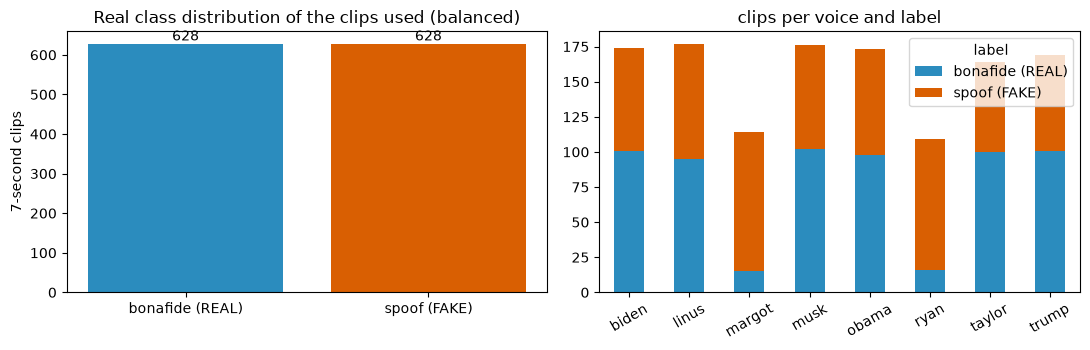

In [7]:
print("feature tensor (clips, time blocks, features):", X_ALL.shape, "| clip-level table (clips, features):", X_ALL.mean(1).shape)
print("26 feature names:", FEATURE_NAMES)
lab_names = {0: "bonafide (REAL)", 1: "spoof (FAKE)"}
print("original label values and counts in the balanced subset:", {lab_names[k]: int(v) for k, v in zip(*np.unique(Y_ALL, return_counts=True))})
print("whole DEEP-VOICE mirror: 628 bonafide + 4,425 spoof = 5,053 fragments of 7 s (the subset keeps all bonafide and draws 628 spoof)")
tab = pd.crosstab(pd.Series(VOICE, name="voice (speaker you hear)"), pd.Series(Y_ALL, name="label").map(lab_names))
display(tab)
print("number of distinct source recordings / conversion pairs:", len(set(STEM)), "(8 real recordings, the rest voice-conversion pairs)")

COL = {0: "#2b8cbe", 1: "#d95f02"}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar([lab_names[0], lab_names[1]], [(Y_ALL == 0).sum(), (Y_ALL == 1).sum()], color=[COL[0], COL[1]])
for i, v in enumerate([(Y_ALL == 0).sum(), (Y_ALL == 1).sum()]): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_title("Real class distribution of the clips used (balanced)"); ax[0].set_ylabel("7-second clips")
tab.plot(kind="bar", stacked=True, ax=ax[1], color=[COL[0], COL[1]], rot=30); ax[1].set_title("clips per voice and label"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

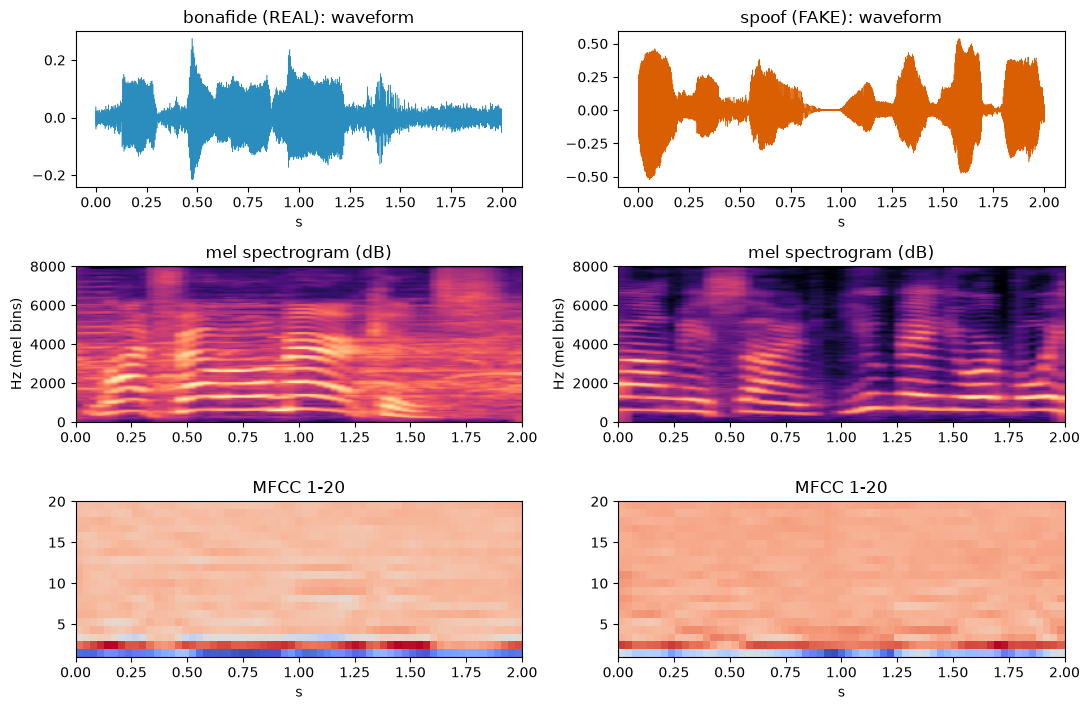

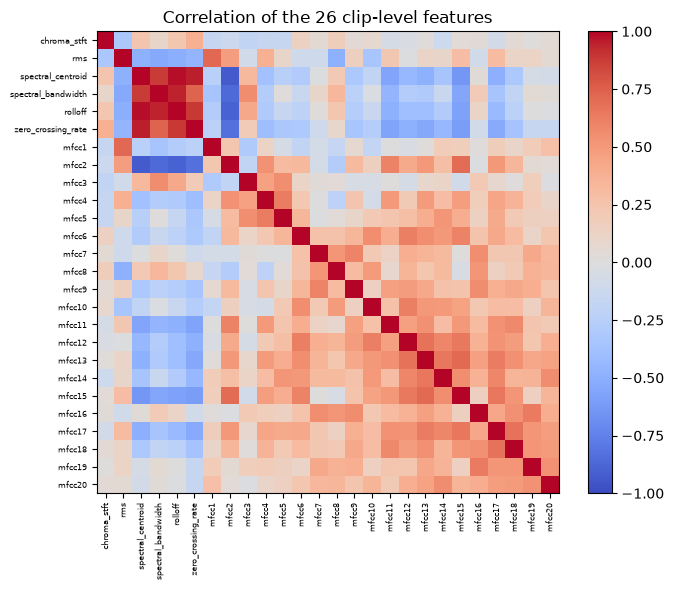

In [8]:
# Fig. 3 of the paper, re-drawn from the first 2 s of one real and one fake fragment: waveform, mel spectrogram (dB), MFCCs
fig, axes = plt.subplots(3, 2, figsize=(11, 7.2))
for j, k in enumerate([0, 1]):
    y = WAVE[k].astype(np.float64); t = np.arange(len(y)) / SR
    axes[0, j].plot(t, y, lw=0.4, color=COL[k]); axes[0, j].set_title(f"{lab_names[k]}: waveform"); axes[0, j].set_xlabel("s")
    db = mel_db(y)
    axes[1, j].imshow(db.T, origin="lower", aspect="auto", extent=[0, len(y) / SR, 0, SR / 2], cmap="magma"); axes[1, j].set_title("mel spectrogram (dB)"); axes[1, j].set_ylabel("Hz (mel bins)")
    mf = dct(db, type=2, axis=1, norm="ortho")[:, :N_MFCC]
    axes[2, j].imshow(mf.T, origin="lower", aspect="auto", extent=[0, len(y) / SR, 1, N_MFCC], cmap="coolwarm"); axes[2, j].set_title("MFCC 1-20"); axes[2, j].set_xlabel("s")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7.2, 6))
C = np.corrcoef(X_ALL.mean(1).T); im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(26)); ax.set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=6); ax.set_yticks(range(26)); ax.set_yticklabels(FEATURE_NAMES, fontsize=6)
ax.set_title("Correlation of the 26 clip-level features"); plt.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout(); plt.show()

explained variance of the two PCA axes (training split): [0.346 0.177]


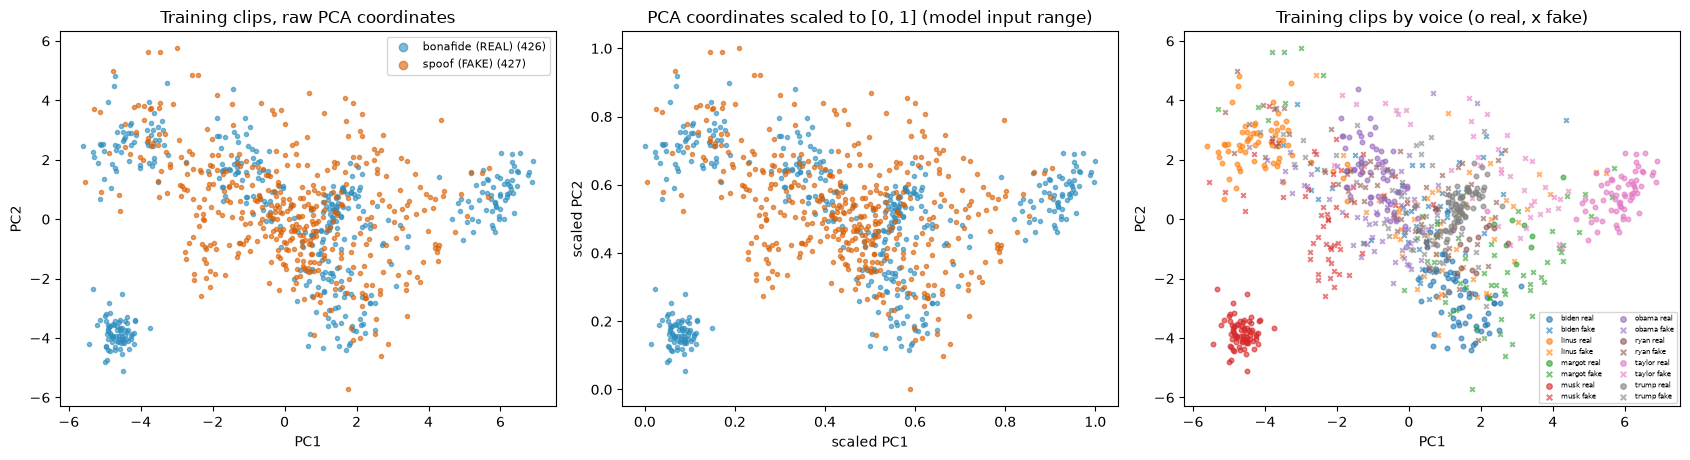

Real and fake clips overlap strongly in the first two PCA axes; the CNN reads the whole (8, 26) sequence, not these two numbers.


In [9]:
# 2-D PCA of the real clips (fitted on the training split only), coloured by ground-truth label and by speaker
clip_mean = X_ALL.mean(1)                                                  # (clips, 26): the quantity DEEP-VOICE's feature table contains
std_clip = StandardScaler().fit(clip_mean[S0.tr])
pca = PCA(n_components=2, random_state=SEED).fit(std_clip.transform(clip_mean[S0.tr]))
P_all = pca.transform(std_clip.transform(clip_mean))                       # raw PCA coordinates of every clip
print("explained variance of the two PCA axes (training split):", pca.explained_variance_ratio_.round(3))
lo, hi = P_all[S0.tr].min(0), P_all[S0.tr].max(0)
P_scaled = np.clip((P_all - lo) / (hi - lo), 0, 1)                         # the [0,1] range in which the CNN receives its inputs
spk = sorted(set(VOICE)); cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))
for ax, XY, ttl, xl in [(axes[0], P_all, "Training clips, raw PCA coordinates", "PC1"), (axes[1], P_scaled, "PCA coordinates scaled to [0, 1] (model input range)", "scaled PC1")]:
    for k in (0, 1):
        m = np.isin(np.arange(len(Y_ALL)), S0.tr) & (Y_ALL == k)
        ax.scatter(XY[m, 0], XY[m, 1], s=9, alpha=0.6, color=COL[k], label=f"{lab_names[k]} ({m.sum()})")
    ax.set_title(ttl); ax.set_xlabel(xl); ax.set_ylabel(xl.replace("1", "2"))
axes[0].legend(markerscale=2, fontsize=8)
for i, s in enumerate(spk):                                               # same coordinates, coloured by whose voice is heard; marker = label
    for k, mk in ((0, "o"), (1, "x")):
        m = np.isin(np.arange(len(Y_ALL)), S0.tr) & (VOICE == s) & (Y_ALL == k)
        axes[2].scatter(P_all[m, 0], P_all[m, 1], s=11, marker=mk, alpha=0.6, color=cmap(i), label=f"{s} {'real' if k == 0 else 'fake'}" if m.any() else None)
axes[2].set_title("Training clips by voice (o real, x fake)"); axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
axes[2].legend(fontsize=5, ncol=2, markerscale=1.2)
plt.tight_layout(); plt.show()
print("Real and fake clips overlap strongly in the first two PCA axes; the CNN reads the whole (8, 26) sequence, not these two numbers.")

## 3. Classical reference models on identical inputs

Besides the classical CNN of the paper, a **random forest** and an **RBF support-vector machine** are trained on the same
min-max-scaled inputs (the flattened `(8 x 26)` sequence, 208 numbers) and, as a second view, on the 26 clip-level means. The SVM's `C`
and the forest are fitted on the training part only; `C` is picked on the validation part. All numbers are test-set numbers.

In [10]:
def metrics(y, pred, score):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(acc=(tp + tn) / len(y), prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), auc=roc_auc_score(y, score), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

RESULTS = []                                  # one dict per (model, seed)
def record(name, S, pred, score, seconds, trainable, **extra):
    r = dict(model=name, seed=S.seed, seconds=seconds, trainable=trainable, **metrics(S.yte, pred, score)); r.update(extra)
    RESULTS.append(r); return r

def run_sklearn(S):
    flat = lambda a: a.reshape(len(a), -1)
    views = {"flattened sequence (208)": (flat(S.Xtr), flat(S.Xva), flat(S.Xte)),
             "clip means (26)": (S.Xtr.mean(1), S.Xva.mean(1), S.Xte.mean(1))}
    for vname, (A, V, Tt) in views.items():
        t = time.time()
        best = max(((accuracy_score(S.yva, SVC(kernel="rbf", C=C, gamma="scale").fit(A, S.ytr).predict(V)), C) for C in (1.0, 10.0, 100.0)))
        m = SVC(kernel="rbf", C=best[1], gamma="scale").fit(A, S.ytr)
        record(f"SVM (RBF), {vname}", S, m.predict(Tt), m.decision_function(Tt), time.time() - t, 0, hp=f"C={best[1]}")
        t = time.time()
        m = RandomForestClassifier(n_estimators=200, random_state=S.seed, n_jobs=2).fit(A, S.ytr)
        record(f"Random forest, {vname}", S, m.predict(Tt), m.predict_proba(Tt)[:, 1], time.time() - t, 0)

SPLITS = [S0] + [make_split(SEED + k) for k in range(1, N_SEEDS)]
for S in SPLITS:
    run_sklearn(S)
display(pd.DataFrame(RESULTS)[["model", "seed", "acc", "prec", "rec", "f1", "auc", "seconds"]].round(4))

,model,seed,acc,prec,rec,f1,auc,seconds
0,"SVM (RBF), flattened sequence (208)",42,0.9802,0.9919,0.9683,0.9799,0.9963,2.9267
1,"Random forest, flattened sequence (208)",42,0.9286,0.9154,0.9444,0.9297,0.9795,16.0872
2,"SVM (RBF), clip means (26)",42,0.9881,1.0000,0.9762,0.9880,0.9993,0.4789
3,"Random forest, clip means (26)",42,0.9524,0.9524,0.9524,0.9524,0.9947,14.2342
4,"SVM (RBF), flattened sequence (208)",43,0.9563,0.9600,0.9524,0.9562,0.9882,2.5543
5,"Random forest, flattened sequence (208)",43,0.9444,0.9375,0.9524,0.9449,0.9806,10.5228
6,"SVM (RBF), clip means (26)",43,0.9881,1.0000,0.9762,0.9880,0.9994,0.4449
7,"Random forest, clip means (26)",43,0.9762,0.9918,0.9603,0.9758,0.9938,6.6607


## 4. A fast exact simulator of the quantum circuit

The circuit has 12 qubits, so its state vector has 4,096 real amplitudes (only $R_y$ and CNOT gates act, starting from
$|0\rangle^{\otimes12}$). Training needs the gradient of the measured probabilities with respect to the angles at every step, for up to
96 blocks. A general-purpose circuit simulator would be needlessly slow on a CPU, so the notebook contains a small **batch-free PyTorch
state-vector simulator** whose operations are differentiable. To be sure it computes *the same quantum circuit* that the
drawing in the next section shows, the section asserts that its output equals the probabilities of a real PennyLane
`default.qubit` QNode, for several block counts and random angles.

In [11]:
N = N_QUBITS
IDX = np.arange(2 ** N)                                          # wire 0 = most significant bit (PennyLane convention)
BITS = torch.tensor(np.stack([(IDX >> (N - 1 - j)) & 1 for j in range(N)], 1), dtype=torch.float32)   # (4096, 12) bit string of every basis state

def cnot_perm(c, t):
    return torch.tensor(IDX ^ (((IDX >> (N - 1 - c)) & 1) << (N - 1 - t)), dtype=torch.long)
CHAIN = cnot_perm(0, 1)
for _j in range(1, N - 1):
    CHAIN = CHAIN[cnot_perm(_j, _j + 1)]                           # CNOT(0,1) then CNOT(1,2) ... CNOT(10,11) as one index permutation

def kron_batch(ms):
    """Kronecker product of a list of batched 2x2 matrices (nb, 2, 2) -> (nb, 2^k, 2^k)."""
    out = ms[0]
    for q in ms[1:]:
        out = torch.einsum("bij,bkl->bikjl", out, q).reshape(out.shape[0], out.shape[1] * 2, out.shape[2] * 2)
    return out

def qnn_probs(phi):
    """phi: (n_block, 12) -> probabilities of the 4096 basis states of  prod_b [CNOT chain . (RY(phi_b0) x ... x RY(phi_b11))] |0...0>."""
    h = N // 2
    c, s = torch.cos(phi / 2), torch.sin(phi / 2)
    m = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)          # (nb, 12, 2, 2): RY matrices of every block
    As = kron_batch([m[:, j] for j in range(h)]).unbind(0)                           # RY on wires 0-5 of block b  (64 x 64)
    Bs = kron_batch([m[:, j] for j in range(h, N)]).unbind(0)                        # RY on wires 6-11 of block b (64 x 64)
    psi = torch.zeros(2 ** h, 2 ** (N - h), dtype=phi.dtype); psi[0, 0] = 1.0        # |0...0> as a 64 x 64 matrix (row = wires 0-5)
    for b in range(phi.shape[0]):
        psi = As[b] @ psi @ Bs[b].T                                                  # all 12 RY rotations of the block
        psi = psi.reshape(-1)[CHAIN].reshape(2 ** h, 2 ** (N - h))                   # the linear CNOT chain
    return psi.reshape(-1) ** 2
print("simulator ready: %d amplitudes, CNOT chain permutation of length %d" % (2 ** N, len(CHAIN)))

simulator ready: 4096 amplitudes, CNOT chain permutation of length 4096


## Quantum Circuit Architecture

The weight generator is one circuit family with a single hyper-parameter, the number of blocks $n_{block}$ (the paper uses 12 to
96). One block is: an $R_y(\phi)$ rotation on each of the 12 qubits followed by CNOT(0,1), CNOT(1,2), ..., CNOT(10,11) (the paper's
"linear layout"). There is **no data input**: the circuit starts in $|0\rangle^{\otimes 12}$ and its 4,096 probabilities are
read out (`qml.probs`). Assumptions where the paper omits details: the initial state, the exact order of the CNOT chain
(0->1, 1->2, ...), uniform random initial angles in $[0,2\pi)$, and that every block has its own 12 angles.

The cell draws the real PennyLane QNode for the smallest block count used here, prints qubits / depth / gates / parameter counts for
every block count, and **asserts that the PyTorch simulator used for training reproduces the QNode's 4,096 probabilities** to
$10^{-6}$ (float32) for each block count.

,blocks,qubits,depth,gates,circuit_params,max_abs_diff_vs_QNode,sum_probs
0,12,12,45,276,144,6.9e-18,1.0
1,24,12,81,552,288,1.0e-17,1.0
2,48,12,153,1104,576,1.6e-17,1.0
3,96,12,297,2208,1152,3.0e-17,1.0


assert OK: the PyTorch simulator used for training equals the PennyLane QNode (4096 probabilities) for every block count above.


Matplotlib is building the font cache; this may take a moment.


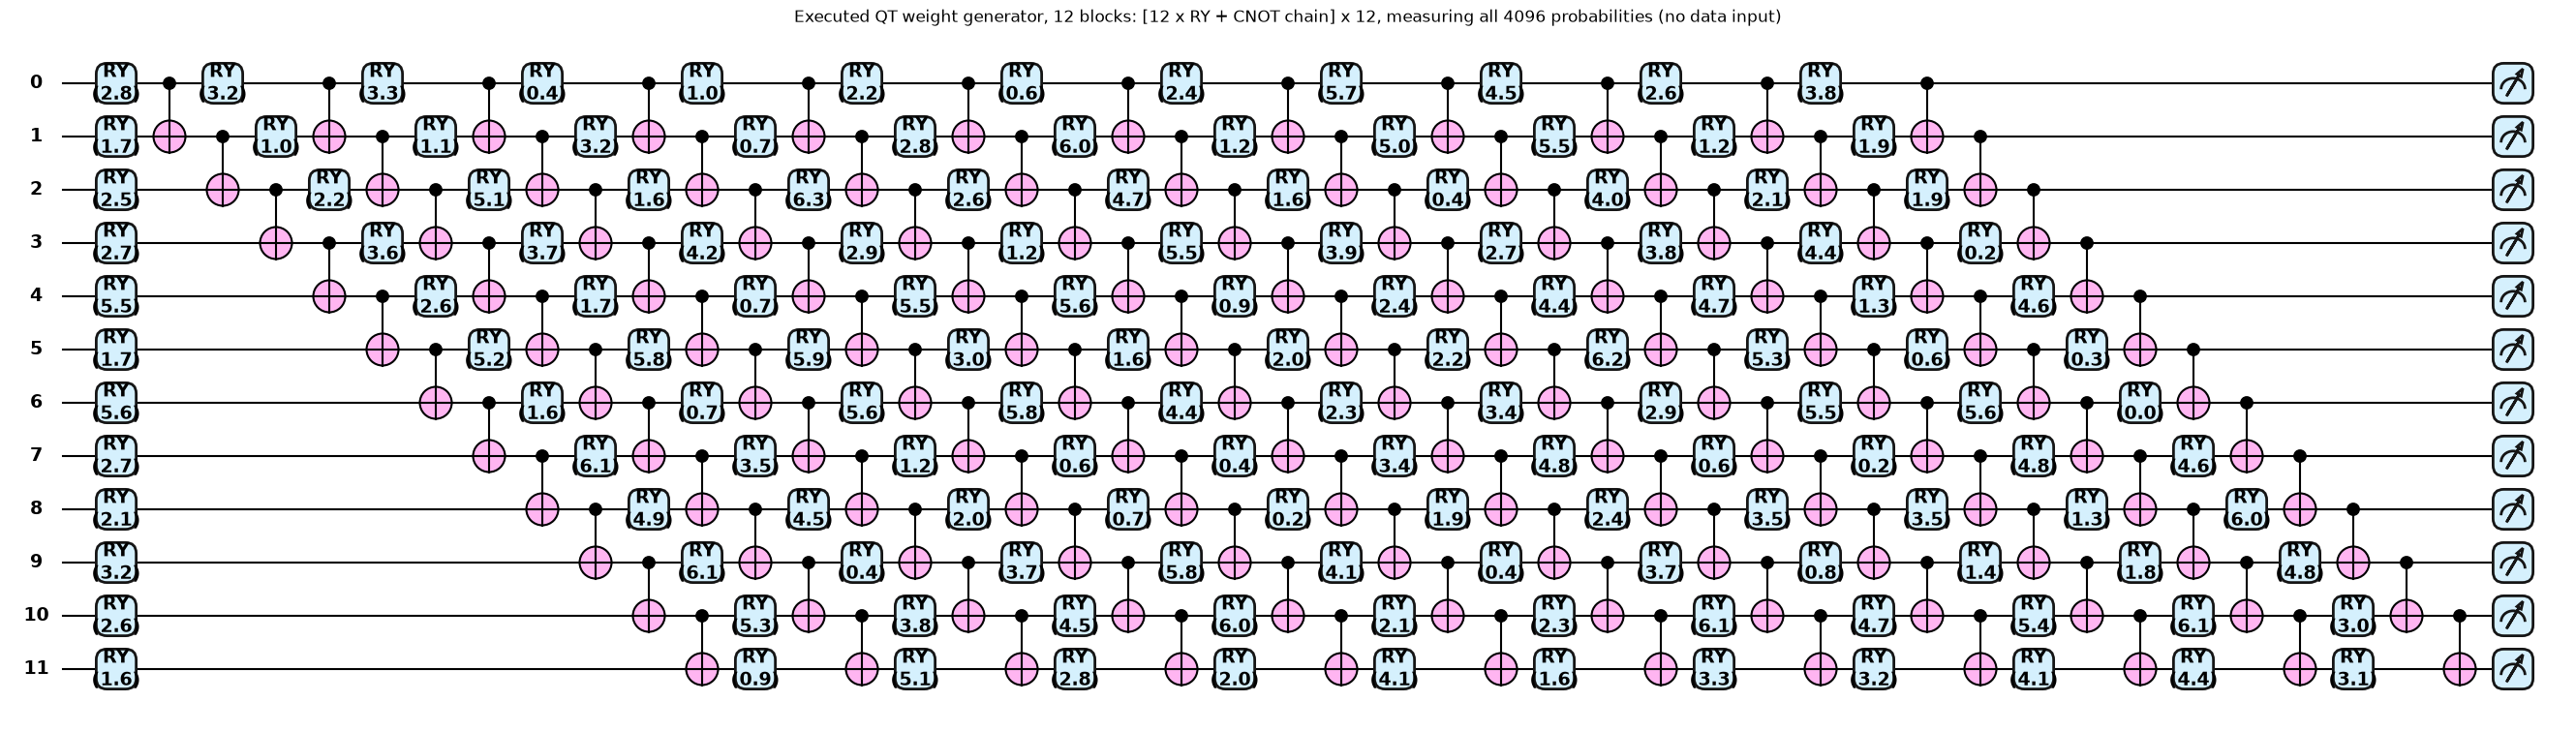

Drawn: 12 blocks. Other block counts repeat the same [RY layer + CNOT chain] block; their depth / gate / parameter counts are in the table above.


In [12]:
def make_qnode(n_block):
    dev = qml.device("default.qubit", wires=N)
    @qml.qnode(dev)
    def circuit(phi):
        for b in range(n_block):
            for j in range(N):
                qml.RY(phi[b, j], wires=j)                       # trainable rotation
            for j in range(N - 1):
                qml.CNOT(wires=[j, j + 1])                       # linear entangling chain
        return qml.probs(wires=range(N))                         # 2**12 probabilities -> weight generator input
    return circuit

rng_c = np.random.default_rng(SEED)
rows = []
for nb in sorted(set(BLOCKS) | {BLOCKS[0]}):
    phi = rng_c.uniform(0, 2 * np.pi, (nb, N)); qn = make_qnode(nb)
    ref = np.asarray(qn(phi)); mine = qnn_probs(torch.tensor(phi, dtype=torch.float64)).numpy()
    assert np.allclose(ref, mine, atol=1e-6), "simulator differs from the PennyLane QNode"
    sp = qml.specs(qn)(phi)["resources"]
    rows.append(dict(blocks=nb, qubits=N, depth=sp.depth, gates=sum(sp.gate_types.values()), circuit_params=phi.size,
                     max_abs_diff_vs_QNode="%.1e" % np.abs(ref - mine).max(), sum_probs=round(float(ref.sum()), 12)))
display(pd.DataFrame(rows))
print("assert OK: the PyTorch simulator used for training equals the PennyLane QNode (4096 probabilities) for every block count above.")

nb0 = BLOCKS[0]
fig, ax = qml.draw_mpl(make_qnode(nb0), decimals=1, style="pennylane")(rng_c.uniform(0, 2 * np.pi, (nb0, N)))
fig.set_size_inches(min(fig.get_size_inches()[0], 60) * 0.55, fig.get_size_inches()[1] * 0.55)
ax.set_title(f"Executed QT weight generator, {nb0} blocks: [12 x RY + CNOT chain] x {nb0}, measuring all 4096 probabilities (no data input)")
plt.show()
print(f"Drawn: {nb0} blocks. Other block counts repeat the same [RY layer + CNOT chain] block; their depth / gate / parameter counts are in the table above.")

## 5. The classical CNN and the Quantum-Train CNN

**Classical CNN (the paper's reference, 3,373 parameters).** Input `(8, 26)` (8 time blocks, 26 features). `Conv1d(26,16,3)` ->
ReLU -> `Conv1d(16,8,3)` -> ReLU -> flatten (8 x 4 = 32) -> `Linear(32,49)` -> ReLU -> `Linear(49,2)`. The layer sizes are a choice; they were
searched so that the parameter count is exactly the paper's 3,373 (1,264 + 392 + 1,617 + 100).

**QT-CNN.** The same network, but its 3,373 parameters are *generated*: the circuit gives 4,096 probabilities $p_i$; for
$i=1,\dots,3373$ the mapping model $G$ (13 -> 20 -> 1 perceptron, 301 parameters) receives $[b_1,\dots,b_{12},\,2^{12}p_i]$ and returns
$\theta_i$; for each of the 8 tensors (4 weight matrices, 4 bias vectors) the raw outputs are standardised and multiplied by one learned
number (the 8 parameters of the scaling model). Trainable: $12\,n_{block}$ angles + 301 + 8. The classical CNN code is shared, so both models are exactly the same function of the
input once the weights are known.

**Parameter-matched control.** A plain classical CNN with (about) as many trainable parameters as the QT model, found by a small search
over `Conv1d(26,c1,3)`, `Conv1d(c1,c2,3)`, `Linear(4*c2,h)`, `Linear(h,2)`. If QT only matched *this*, the quantum weight generator
would add nothing over simply using a smaller network.

In [13]:
CNN_SHAPES = [(16, 26, 3), (16,), (8, 16, 3), (8,), (49, 32), (49,), (2, 49), (2,)]     # CHOICE: sized so that the total is the paper's 3,373
CNN_SIZES = [int(np.prod(s)) for s in CNN_SHAPES]; M_CNN = sum(CNN_SIZES)
PAPER_CNN_PARAMS, MAPPING_PARAMS, SCALING_PARAMS = 3373, 301, 8
assert M_CNN == PAPER_CNN_PARAMS <= 2 ** N

def cnn_forward(x, W):                                         # x: (B, T, 26); W: list of 8 tensors (generic widths)
    x = x.transpose(1, 2)
    x = F.relu(F.conv1d(x, W[0], W[1])); x = F.relu(F.conv1d(x, W[2], W[3]))
    return F.relu(x.flatten(1) @ W[4].T + W[5]) @ W[6].T + W[7]

def init_tensors(shapes, seed):
    g = torch.Generator().manual_seed(seed); out = []
    for sh in shapes:
        fan = int(np.prod(sh[1:])) if len(sh) > 1 else 1
        out.append(nn.Parameter(torch.randn(*sh, generator=g) * math.sqrt(2.0 / fan)) if len(sh) > 1 else nn.Parameter(torch.zeros(*sh)))
    return out

class ClassicCNN(nn.Module):
    def __init__(self, shapes, seed):
        super().__init__(); self.p = nn.ParameterList(init_tensors(shapes, seed))
    def forward(self, x): return cnn_forward(x, list(self.p))
    def n_trainable(self): return sum(p.numel() for p in self.parameters())

class QTCNN(nn.Module):
    def __init__(self, n_block, seed):
        super().__init__(); g = torch.Generator().manual_seed(seed)
        self.phi = nn.Parameter(torch.rand(n_block, N, generator=g) * 2 * math.pi)                # QNN angles
        torch.manual_seed(seed); self.G = nn.Sequential(nn.Linear(N + 1, 20), nn.Tanh(), nn.Linear(20, 1))   # mapping model: 13*20+20 + 20+1 = 301
        # scaling model: one multiplier per tensor, initialised to the He standard deviation of that tensor (CHOICE)
        self.scale = nn.Parameter(torch.tensor([math.sqrt(2.0 / int(np.prod(sh[1:]))) if len(sh) > 1 else 0.05 for sh in CNN_SHAPES]))
    def generate(self):
        p = qnn_probs(self.phi)[:M_CNN]                                                          # the first 3373 of the 4096 probabilities
        theta = self.G(torch.cat([BITS[:M_CNN], (p * 2 ** N).unsqueeze(1)], 1)).squeeze(1)       # mapping model, one raw weight per basis state
        out, off = [], 0
        for k, (sh, sz) in enumerate(zip(CNN_SHAPES, CNN_SIZES)):
            seg = theta[off:off + sz]; seg = (seg - seg.mean()) / (seg.std() + 1e-6)             # CHOICE: standardise each tensor's raw weights ...
            out.append((self.scale[k] * seg).reshape(sh)); off += sz                              # ... then the scaling model sets its size
        return out
    def forward(self, x): return cnn_forward(x, self.generate())
    def n_trainable(self): return sum(p.numel() for p in self.parameters())
    def n_parts(self): return self.phi.numel(), sum(p.numel() for p in self.G.parameters()), self.scale.numel()

def matched_shapes(target):
    cands = []
    for c1 in range(2, 17):
        for c2 in range(2, 17):
            for h in range(2, 65):
                n = 26 * 3 * c1 + c1 + c1 * 3 * c2 + c2 + 4 * c2 * h + h + 2 * h + 2
                if abs(n - target) <= 0.01 * target:
                    cands.append((c1 * c2 * h, abs(n - target) * -1, c1, c2, h))       # CHOICE: within 1 % of the target, most balanced (largest c1*c2*h)
    _, _, c1, c2, h = max(cands)
    return [(c1, 26, 3), (c1,), (c2, c1, 3), (c2,), (h, 4 * c2), (h,), (2, h), (2,)]

q0 = QTCNN(12, SEED)
assert q0.n_parts() == (12 * N, MAPPING_PARAMS, SCALING_PARAMS), q0.n_parts()
print("classical CNN parameters:", ClassicCNN(CNN_SHAPES, SEED).n_trainable(), "(paper: 3373)")
print("QT-CNN parts for 12 blocks (angles, mapping model, scaling model):", q0.n_parts(), "-> trainable", q0.n_trainable(), "(paper: 456)")
print("QT-CNN trainable parameters by block count:", {nb: 12 * nb + MAPPING_PARAMS + SCALING_PARAMS for nb in BLOCKS}, "(paper: 456 ... 1464 for 12 ... 96 blocks)")
MATCH = {nb: matched_shapes(12 * nb + MAPPING_PARAMS + SCALING_PARAMS) for nb in BLOCKS}
print("parameter-matched classical CNNs (c1, c2, h):", {nb: (s[0][0], s[2][0], s[4][0], ClassicCNN(s, SEED).n_trainable()) for nb, s in MATCH.items()})

classical CNN parameters: 3373 (paper: 3373)
QT-CNN parts for 12 blocks (angles, mapping model, scaling model): (144, 301, 8) -> trainable 453 (paper: 456)
QT-CNN trainable parameters by block count: {12: 453, 24: 597, 48: 885, 96: 1461} (paper: 456 ... 1464 for 12 ... 96 blocks)


parameter-matched classical CNNs (c1, c2, h): {12: (2, 4, 14, 454), 24: (3, 4, 17, 602), 48: (5, 5, 18, 891), 96: (8, 4, 39, 1475)}


## 6. Training

All models use the same data, optimiser (Adam), loss (cross-entropy), batch size and number of epochs. After every epoch the
validation accuracy is computed; the weights of the best validation epoch are kept for the final test evaluation (no test-set
peeking). For the QT-CNN every step runs the circuit simulation, the mapping model and the CNN, and back-propagates through all
three, which is the exact gradient the parameter-shift rule would give on a noise-free device.

In [14]:
def to_t(a, dt=torch.float32): return torch.tensor(a, dtype=dt)

def fit(model, S, epochs, lr, tag):
    Xtr, ytr, Xva, yva = to_t(S.Xtr), to_t(S.ytr, torch.long), to_t(S.Xva), to_t(S.yva, torch.long)
    opt = torch.optim.Adam(model.parameters(), lr=lr); g = torch.Generator().manual_seed(S.seed)
    best = (-1.0, None, 0); hist = []
    t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(ytr), generator=g); tot = 0.0
        for a in range(0, len(perm), BATCH):
            b = perm[a:a + BATCH]
            loss = F.cross_entropy(model(Xtr[b]), ytr[b]); opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        with torch.no_grad():
            tr_acc = (model(Xtr).argmax(1) == ytr).float().mean().item(); va_acc = (model(Xva).argmax(1) == yva).float().mean().item()
        hist.append((tot / len(ytr), tr_acc, va_acc))
        if va_acc > best[0]:
            best = (va_acc, {k: v.detach().clone() for k, v in model.state_dict().items()}, ep)
    model.load_state_dict(best[1])
    return pd.DataFrame(hist, columns=["loss", "train_acc", "val_acc"]), best[2], time.time() - t0

@torch.no_grad()
def evaluate(model, S):
    logits = model(to_t(S.Xte)); p = torch.softmax(logits, -1)[:, 1].numpy()
    return (p > 0.5).astype(int), p

CURVES, FROZEN = {}, {}
def run_nn(S, name, model, lr):
    hist, best_ep, secs = fit(model, S, EPOCHS, lr, name)
    pred, p = evaluate(model, S)
    with torch.no_grad():
        tr_acc = (model(to_t(S.Xtr)).argmax(1).numpy() == S.ytr).mean()
    r = record(name, S, pred, p, secs, model.n_trainable(), train_acc=float(tr_acc), best_epoch=best_ep)
    if S.seed == SEED:
        CURVES[name] = hist; FROZEN[name] = (model, S)
    return r

for S in SPLITS:
    r = run_nn(S, "Classical CNN (3373 params)", ClassicCNN(CNN_SHAPES, S.seed), LR_CNN)
    print(f"seed {S.seed} classical CNN: test acc {r['acc']:.4f}  train acc {r['train_acc']:.4f}  ({r['seconds']:.0f} s, best epoch {r['best_epoch']})")
    for nb in BLOCKS:
        r = run_nn(S, f"Param-matched classical CNN ({nb} blocks)", ClassicCNN(MATCH[nb], S.seed), LR_CNN)
        print(f"seed {S.seed} matched CNN ~{nb} blocks ({r['trainable']} params): test acc {r['acc']:.4f}  ({r['seconds']:.0f} s)")
        r = run_nn(S, f"QT-CNN ({nb} blocks)", QTCNN(nb, S.seed), LR_QT)
        print(f"seed {S.seed} QT-CNN {nb} blocks ({r['trainable']} params): test acc {r['acc']:.4f}  train acc {r['train_acc']:.4f}  ({r['seconds']:.0f} s, best epoch {r['best_epoch']})")

seed 42 classical CNN: test acc 0.9365  train acc 1.0000  (29 s, best epoch 98)


seed 42 matched CNN ~12 blocks (454 params): test acc 0.8452  (32 s)


seed 42 QT-CNN 12 blocks (453 params): test acc 0.8532  train acc 0.8699  (173 s, best epoch 85)


seed 42 matched CNN ~24 blocks (602 params): test acc 0.7698  (27 s)


seed 42 QT-CNN 24 blocks (597 params): test acc 0.8810  train acc 0.8957  (298 s, best epoch 72)


...

seed 43 QT-CNN 24 blocks (597 params): test acc 0.8452  train acc 0.8593  (539 s, best epoch 72)


seed 43 matched CNN ~48 blocks (891 params): test acc 0.7659  (58 s)


seed 43 QT-CNN 48 blocks (885 params): test acc 0.8730  train acc 0.9109  (900 s, best epoch 95)


seed 43 matched CNN ~96 blocks (1475 params): test acc 0.8849  (47 s)


seed 43 QT-CNN 96 blocks (1461 params): test acc 0.8730  train acc 0.8980  (900 s, best epoch 87)


## 7. Inference is purely classical

The central practical claim of the Quantum-Train idea is that after training the weights can be generated **once**, stored, and the CNN
then runs without any quantum circuit. The cell below takes a trained QT-CNN, calls the generator one last time, copies the 3,373
numbers into a plain classical CNN and checks that the predictions on the whole test set are identical.

In [15]:
key = f"QT-CNN ({BLOCKS[0]} blocks)"
qt_model, S_ = FROZEN[key]
with torch.no_grad():
    W = [w.detach().clone() for w in qt_model.generate()]
plain = ClassicCNN(CNN_SHAPES, SEED)
for p_, w_ in zip(plain.p, W): p_.data.copy_(w_)
with torch.no_grad():
    p_qt = torch.softmax(qt_model(to_t(S_.Xte)), -1).numpy(); p_cl = torch.softmax(plain(to_t(S_.Xte)), -1).numpy()
assert np.allclose(p_qt, p_cl, atol=1e-6) and (p_qt.argmax(1) == p_cl.argmax(1)).all()
print(f"{key}: frozen weights ({sum(w.numel() for w in W)} numbers) in a plain CNN give the same {len(S_.yte)} test predictions "
      f"(max |difference| of class probabilities {np.abs(p_qt - p_cl).max():.1e}). The circuit is not needed at inference.")
print("test accuracy of the frozen classical copy:", round(float((p_cl.argmax(1) == S_.yte).mean()), 4))

QT-CNN (12 blocks): frozen weights (3373 numbers) in a plain CNN give the same 252 test predictions (max |difference| of class probabilities 0.0e+00). The circuit is not needed at inference.
test accuracy of the frozen classical copy: 0.8532


## 8. Results, figures and the paper's Fig. 4

Test-set results (mean over 2 seed(s); 252 test clips, balanced classes; fake = positive)


,trainable,acc,prec,rec,f1,auc,sec
model,,,,,,,
Classical CNN (3373 params),3373,0.9187 +- 0.0253,0.9344 +- 0.0067,0.9008 +- 0.0617,0.9166 +- 0.0288,0.9751 +- 0.0031,37
QT-CNN (12 blocks),453,0.8492 +- 0.0056,0.8392 +- 0.0204,0.8651 +- 0.0449,0.8513 +- 0.0113,0.9002 +- 0.0005,251
Param-matched classical CNN (12 blocks),454,0.8214 +- 0.0337,0.8040 +- 0.0478,0.8611 +- 0.1740,0.8245 +- 0.0561,0.9062 +- 0.0086,37
QT-CNN (24 blocks),597,0.8631 +- 0.0253,0.8486 +- 0.0373,0.8849 +- 0.0056,0.8662 +- 0.0221,0.9283 +- 0.0352,418
Param-matched classical CNN (24 blocks),602,0.7917 +- 0.0309,0.7836 +- 0.0254,0.8056 +- 0.0393,0.7944 +- 0.0322,0.8659 +- 0.0164,49
QT-CNN (48 blocks),885,0.9087 +- 0.0505,0.8968 +- 0.0576,0.9246 +- 0.0393,0.9104 +- 0.0487,0.9591 +- 0.0303,685
Param-matched classical CNN (48 blocks),891,0.8075 +- 0.0589,0.7969 +- 0.0006,0.8254 +- 0.1571,0.8072 +- 0.0765,0.8838 +- 0.0093,43
QT-CNN (96 blocks),1461,0.9028 +- 0.0421,0.9114 +- 0.1002,0.9008 +- 0.0281,0.9038 +- 0.0354,0.9601 +- 0.0253,1129
Param-matched classical CNN (96 blocks),1475,0.9008 +- 0.0224,0.9181 +- 0.0157,0.8810 +- 0.0673,0.8982 +- 0.0276,0.9599 +- 0.0122,38


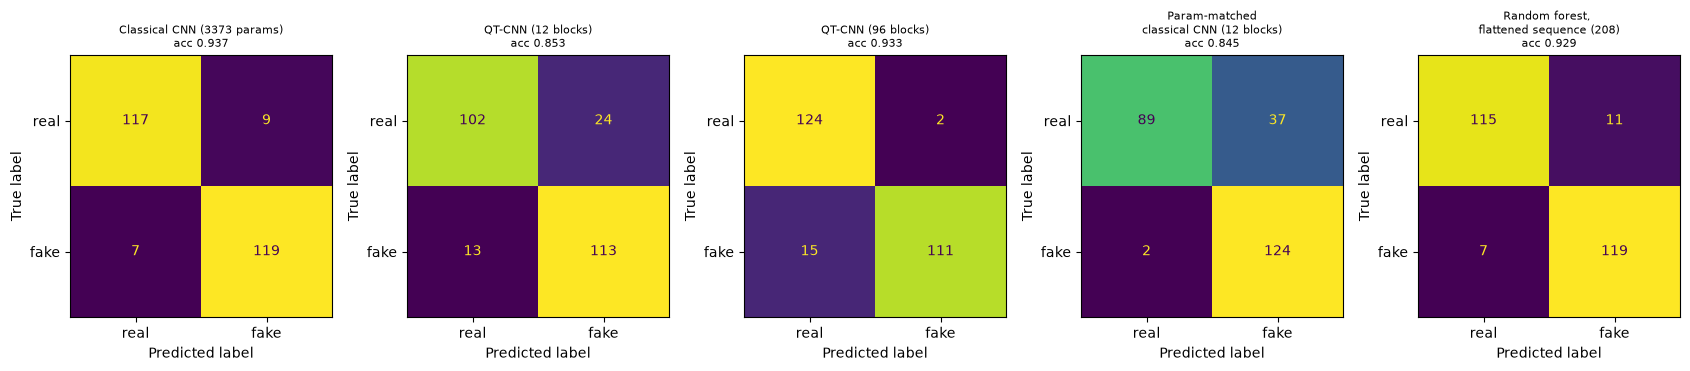

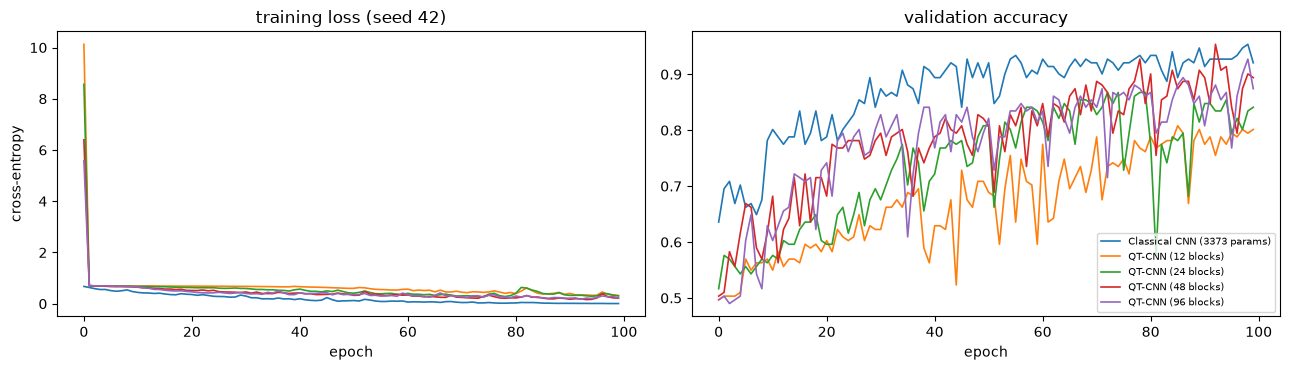

In [16]:
res = pd.DataFrame(RESULTS)
order = ["Classical CNN (3373 params)"] + [f"{k} ({nb} blocks)" for nb in BLOCKS for k in ("QT-CNN", "Param-matched classical CNN")] + \
        [m for m in res.model.unique() if m.startswith(("SVM", "Random"))]
agg = res.groupby("model")[["acc", "prec", "rec", "f1", "auc", "seconds"]].agg(["mean", "std"]).reindex(order)
tab = pd.DataFrame({"trainable": res.groupby("model")["trainable"].first().reindex(order)})
for m in ["acc", "prec", "rec", "f1", "auc"]:
    tab[m] = [f"{agg.loc[k, (m, 'mean')]:.4f}" + (f" +- {agg.loc[k, (m, 'std')]:.4f}" if N_SEEDS > 1 else "") for k in order]
tab["sec"] = [f"{agg.loc[k, ('seconds', 'mean')]:.0f}" for k in order]
print(f"Test-set results (mean over {N_SEEDS} seed(s); {len(S0.te)} test clips, balanced classes; fake = positive)")
display(tab)

# confusion matrices (seed 0) of the main models
key_models = ["Classical CNN (3373 params)", f"QT-CNN ({BLOCKS[0]} blocks)", f"QT-CNN ({BLOCKS[-1]} blocks)", f"Param-matched classical CNN ({BLOCKS[0]} blocks)", "Random forest, flattened sequence (208)"]
fig, axes = plt.subplots(1, len(key_models), figsize=(3.4 * len(key_models), 3.5))
for ax, k in zip(axes, key_models):
    r = res[(res.model == k) & (res.seed == SEED)].iloc[0]
    ConfusionMatrixDisplay(np.array([[r.tn, r.fp], [r.fn, r.tp]]), display_labels=["real", "fake"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(k.replace(" classical", "\nclassical").replace("flattened", "\nflattened") + f"\nacc {r.acc:.3f}", fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for k in [key_models[0]] + [f"QT-CNN ({nb} blocks)" for nb in BLOCKS]:
    ax[0].plot(CURVES[k]["loss"].values, label=k, lw=1.2); ax[1].plot(CURVES[k]["val_acc"].values, label=k, lw=1.2)
ax[0].set_title("training loss (seed %d)" % SEED); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy")
ax[1].set_title("validation accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

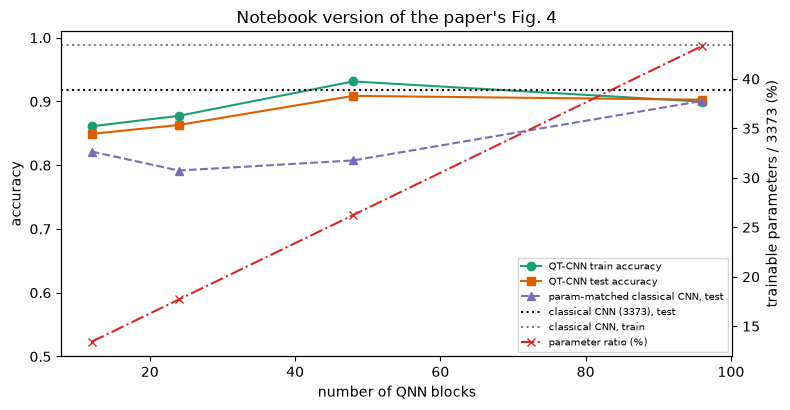

In [17]:
# Fig. 4 of the paper re-drawn: accuracy of QT-CNN versus the classical CNN over the number of QNN blocks, and the parameter ratio
qt = res[res.model.str.startswith("QT-CNN")].copy(); qt["blocks"] = qt.model.str.extract(r"\((\d+) blocks")[0].astype(int)
g = qt.groupby("blocks")[["acc", "train_acc"]].mean()
cl = res[res.model == "Classical CNN (3373 params)"][["acc", "train_acc"]].mean()
mt = res[res.model.str.startswith("Param-matched")].copy(); mt["blocks"] = mt.model.str.extract(r"~?\((\d+) blocks")[0].astype(int)
gm = mt.groupby("blocks")["acc"].mean()
ratio = pd.Series({nb: (12 * nb + MAPPING_PARAMS + SCALING_PARAMS) / PAPER_CNN_PARAMS for nb in BLOCKS})
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(g.index, g.train_acc, "o-", label="QT-CNN train accuracy", color="#1b9e77"); ax.plot(g.index, g.acc, "s-", label="QT-CNN test accuracy", color="#d95f02")
ax.plot(gm.index, gm.values, "^--", label="param-matched classical CNN, test", color="#7570b3")
ax.axhline(cl.acc, color="k", ls=":", label="classical CNN (3373), test"); ax.axhline(cl.train_acc, color="grey", ls=":", label="classical CNN, train")
ax.set_xlabel("number of QNN blocks"); ax.set_ylabel("accuracy"); ax.set_ylim(min(0.5, g.acc.min() - 0.05), 1.01)
ax2 = ax.twinx(); ax2.plot(ratio.index, 100 * ratio.values, "x-.", color="tab:red", label="parameter ratio (%)"); ax2.set_ylabel("trainable parameters / 3373 (%)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower right")
ax.set_title("Notebook version of the paper's Fig. 4"); plt.tight_layout(); plt.show()

## 9. A leakage check: hold out the last fragments of every recording

The 7-second fragments of one long recording are numbered in time order (`frag0`, `frag1`, ...) and neighbours are very similar
(same speaker, microphone, room, voice-conversion model). A *random* split, as in the paper, puts neighbours on both sides. Here a
second split keeps the **last 20 % of the fragments of every recording / conversion pair as the test set** (a contiguous block in time, so no test
fragment has its immediate neighbour in training), the rest is split randomly into training and validation. Every voice is still
seen in training. This is not in the paper; it shows how much of the (high) accuracy depends on near-duplicate neighbours. Only the
classical CNN, one QT-CNN (smallest circuit), the matched CNN, the forest and the SVM are repeated, once.

In [18]:
FRAG = np.array([int(re.search(r"_frag(\d+)\.wav$", p).group(1)) for p in PATHS])

def block_split(seed):
    te = []
    for st in sorted(set(STEM)):
        ii = np.where(STEM == st)[0]; ii = ii[np.argsort(FRAG[ii])]
        te += list(ii[len(ii) - max(1, int(round(0.2 * len(ii)))):])            # the last 20 % of this recording's fragments
    te = np.array(sorted(te)); rest = np.setdiff1d(np.arange(len(Y_ALL)), te)
    tr, va = train_test_split(rest, test_size=VAL_SIZE, stratify=Y_ALL[rest], random_state=seed)
    sc = MinMaxScaler().fit(X_ALL[tr].reshape(-1, 26))
    f = lambda ii: np.clip(sc.transform(X_ALL[ii].reshape(-1, 26)), 0, 1).reshape(X_ALL[ii].shape).astype(np.float32)
    return SimpleNamespace(seed=seed, tr=tr, va=va, te=te, Xtr=f(tr), Xva=f(va), Xte=f(te), ytr=Y_ALL[tr], yva=Y_ALL[va], yte=Y_ALL[te])

SG = block_split(SEED)
print(f"block split: train {len(SG.tr)}, validation {len(SG.va)}, test {len(SG.te)} clips (last fragments of {len(set(STEM))} recordings / pairs); "
      f"fake share in test {SG.yte.mean():.2f}")
GRES = []
def grec(name, pred, score, trainable):
    GRES.append(dict(model=name, trainable=trainable, **{k: v for k, v in metrics(SG.yte, pred, score).items() if k in ("acc", "prec", "rec", "f1", "auc")}))
for name, mdl, lr in [("Classical CNN (3373 params)", ClassicCNN(CNN_SHAPES, SEED), LR_CNN),
                      (f"QT-CNN ({BLOCKS[0]} blocks)", QTCNN(BLOCKS[0], SEED), LR_QT),
                      (f"Param-matched classical CNN ({BLOCKS[0]} blocks)", ClassicCNN(MATCH[BLOCKS[0]], SEED), LR_CNN)]:
    fit(mdl, SG, EPOCHS, lr, name); pr, p = evaluate(mdl, SG); grec(name, pr, p, mdl.n_trainable())
A, Tt = SG.Xtr.reshape(len(SG.Xtr), -1), SG.Xte.reshape(len(SG.Xte), -1)
m = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(A, SG.ytr); grec("Random forest, flattened sequence (208)", m.predict(Tt), m.predict_proba(Tt)[:, 1], 0)
m = SVC(kernel="rbf", C=10.0, gamma="scale").fit(A, SG.ytr); grec("SVM (RBF), flattened sequence (208)", m.predict(Tt), m.decision_function(Tt), 0)
gtab = pd.DataFrame(GRES).set_index("model")
rand_acc = res[res.seed == SEED].set_index("model")["acc"]
gtab["acc with random split (main table)"] = [rand_acc.get(k, np.nan) for k in gtab.index]
display(gtab.round(4))

block split: train 847, validation 150, test 259 clips (last fragments of 63 recordings / pairs); fake share in test 0.52


,trainable,acc,prec,rec,f1,auc,acc with random split (main table)
model,,,,,,,
Classical CNN (3373 params),3373,0.9344,0.9209,0.9552,0.9377,0.9906,0.9365
QT-CNN (12 blocks),453,0.8340,0.8138,0.8806,0.8459,0.8767,0.8532
Param-matched classical CNN (12 blocks),454,0.8494,0.8740,0.8284,0.8506,0.9088,0.8452
"Random forest, flattened sequence (208)",0,0.9073,0.8819,0.9478,0.9137,0.9600,0.9286
"SVM (RBF), flattened sequence (208)",0,0.9421,0.9343,0.9552,0.9446,0.9801,0.9802


## 10. Side by side with the paper and a verdict per claim

In [19]:
claims = []
def claim(text, paper, ours, verdict, note=""):
    claims.append(dict(claim=text, paper=paper, notebook=ours, verdict=verdict, note=note))

mean_acc = res.groupby("model")["acc"].mean(); mean_tr = res.groupby("model")["train_acc"].mean()
ncls = int(ClassicCNN(CNN_SHAPES, SEED).n_trainable())
claim("Classical CNN has 3,373 parameters", "3373", str(ncls), "reproduced" if ncls == 3373 else "not reached", "by construction (layer sizes were searched to hit it)")
n_map = sum(p.numel() for p in QTCNN(12, SEED).G.parameters()); n_sc = QTCNN(12, SEED).scale.numel()
claim("Mapping model has 301 parameters, scaling model 8", "301 / 8", f"{n_map} / {n_sc}", "reproduced" if (n_map, n_sc) == (301, 8) else "not reached", "13->20->1 perceptron; one scale per tensor")
for nb, pp in ((12, 456), (96, 1464)):
    ours = 12 * nb + 309
    claim(f"QT trainable parameters at {nb} blocks", str(pp), str(ours), "reproduced" if abs(ours - pp) / pp <= 0.01 else "not reached",
          f"differs by {ours - pp:+d}; origin of the paper's extra 3 parameters unknown")
for nb, pr in ((12, 13.5), (96, 43.4)):
    ours = 100 * (12 * nb + 309) / 3373
    claim(f"Parameter ratio at {nb} blocks", f"{pr} %", f"{ours:.1f} %", "reproduced" if abs(ours - pr) <= 0.5 else "not reached")
red96 = 100 * (1 - (12 * 96 + 309) / 3373); red12 = 100 * (1 - (12 * 12 + 309) / 3373); nb70 = int((0.30 * 3373 - 309) // 12)
claim("'Up to 70 % parameter reduction' / '70 % efficiency at 96 blocks' (abstract, Sec. IV-C)", "70 % at 96 blocks",
      f"reduction {red12:.1f} % at 12 blocks, {red96:.1f} % at 96 blocks; >= 70 % only up to {nb70} blocks",
      "not reached" if red96 < 69.5 else "reproduced", "the paper's own parameter counts give 56.6 % at 96 blocks, not 70 %")
for nb in BLOCKS:
    d = mean_acc[f"QT-CNN ({nb} blocks)"] - mean_acc["Classical CNN (3373 params)"]
    claim(f"QT-CNN test accuracy comparable to the classical CNN, {nb} blocks (within {TOL_ACC})", "'closely aligned' (Fig. 4, no numbers)",
          f"QT {mean_acc[f'QT-CNN ({nb} blocks)']:.4f} vs CNN {mean_acc['Classical CNN (3373 params)']:.4f} (diff {d:+.4f})",
          "reproduced" if abs(d) <= TOL_ACC else ("exceeded" if d > 0 else "not reached"))
hi_ok = all(mean_acc[f"QT-CNN ({nb} blocks)"] >= 0.90 and mean_tr[f"QT-CNN ({nb} blocks)"] >= 0.90 for nb in BLOCKS)
claim("QT keeps 'consistently high' training and test accuracy for all block counts (read as >= 0.90)", "qualitative",
      ", ".join(f"{nb}: {mean_tr[f'QT-CNN ({nb} blocks)']:.3f}/{mean_acc[f'QT-CNN ({nb} blocks)']:.3f}" for nb in BLOCKS), "reproduced" if hi_ok else "not reached", "train/test accuracy per block count")
claim("Inference runs on classical hardware (weights generated once)", "Fig. 1, Sec. I", "frozen weights give identical predictions (assert above)", "reproduced")
claim("Exact accuracy values of Fig. 4", "only as plotted curves", "-", "cannot be checked", "no numbers in the text")
claim("QT-CNN improves 'robustness against adversarial inputs' (Sec. I)", "stated, no experiment", "not tested", "cannot be checked")
mm = [mean_acc[f"QT-CNN ({nb} blocks)"] - mean_acc[f"Param-matched classical CNN ({nb} blocks)"] for nb in BLOCKS]
claim("(extra) QT beats a plain classical CNN with the same number of trainable parameters", "not claimed", f"QT - matched CNN accuracy: {[round(x, 4) for x in mm]}",
      "reproduced" if all(x > TOL_ACC / 2 for x in mm) else "not reached", "tested here as a fair control; 'reproduced' only if QT is ahead at every size")
cl_df = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 110)
display(cl_df)
print(cl_df.verdict.value_counts().to_dict())

,claim,paper,notebook,verdict,note
0,"Classical CNN has 3,373 parameters",3373,3373,reproduced,by construction (layer sizes were searched to hit it)
1,"Mapping model has 301 parameters, scaling model 8",301 / 8,301 / 8,reproduced,13->20->1 perceptron; one scale per tensor
2,QT trainable parameters at 12 blocks,456,453,reproduced,differs by -3; origin of the paper's extra 3 parameters unknown
3,QT trainable parameters at 96 blocks,1464,1461,reproduced,differs by -3; origin of the paper's extra 3 parameters unknown
4,Parameter ratio at 12 blocks,13.5 %,13.4 %,reproduced,
5,Parameter ratio at 96 blocks,43.4 %,43.3 %,reproduced,
6,"'Up to 70 % parameter reduction' / '70 % efficiency at 96 blocks' (abstract, Sec. IV-C)",70 % at 96 blocks,"reduction 86.6 % at 12 blocks, 56.7 % at 96 blocks; >= 70 % only up to 58 blocks",not reached,"the paper's own parameter counts give 56.6 % at 96 blocks, not 70 %"
7,"QT-CNN test accuracy comparable to the classical CNN, 12 blocks (within 0.02)","'closely aligned' (Fig. 4, no numbers)",QT 0.8492 vs CNN 0.9187 (diff -0.0694),not reached,
8,"QT-CNN test accuracy comparable to the classical CNN, 24 blocks (within 0.02)","'closely aligned' (Fig. 4, no numbers)",QT 0.8631 vs CNN 0.9187 (diff -0.0556),not reached,
9,"QT-CNN test accuracy comparable to the classical CNN, 48 blocks (within 0.02)","'closely aligned' (Fig. 4, no numbers)",QT 0.9087 vs CNN 0.9187 (diff -0.0099),reproduced,


{'reproduced': 9, 'not reached': 5, 'cannot be checked': 2}


## Reading the paper critically

* **No numbers to compare.** The paper's accuracy results exist only as the curves of Fig. 4. The checkable content is the parameter arithmetic
  (reproduced, up to 3 unexplained parameters) and the relative statement "QT is comparable to the CNN", which is tested above.
* **"Up to 70 % parameter reduction" does not match the paper's own table of counts.** 456 to 1,464 parameters out of 3,373 is a reduction of 86.5 % (12
  blocks) down to 56.6 % (96 blocks). The abstract's number and the "70 % at 96 blocks" sentence cannot both be right; the ratio, not the reduction,
  grows with the block count. In this notebook (two seeds, 100 epochs) the accuracy of the QT-CNN is **not** flat: it rises from about 0.85 (12 blocks) and 0.86
  (24 blocks) to about 0.91 (48 blocks) and 0.90 (96 blocks), against 0.92 for the classical CNN. "Comparable" is therefore reached only from 48 blocks on (by then the parameter reduction is 74 % at 48 blocks and 57 % at 96 blocks),
  and the seed-to-seed standard deviation (up to 0.05) is as large as most of the differences.
* **A comparison with a small plain network is missing.** The CNN has only 3,373 parameters, which is already tiny. The parameter-matched classical CNN above is the fair
  comparison. Here the QT-CNN is ahead of it by 2.8, 7.1 and 10.1 accuracy points at 12, 24 and 48 blocks (about 450, 600 and 890 parameters), a gap larger than the seed spread for the
  last two sizes, and tied at 96 blocks (0.903 versus 0.901). So in this replication the generator does help at small sizes; whether that comes from the quantum circuit or from
  the weight-sharing structure of the 301-parameter mapping model is not separated by the paper or here (exercise 2 does it). The match is also not perfect: the matched networks are
  narrow (for example 2 and 4 channels) because the first convolution alone costs 79 parameters per channel.
* **The dataset is easy and the split is generous.** DEEP-VOICE is separable with simple spectral features; an RBF SVM on the 26 clip means reaches 0.988 accuracy, higher
  than every neural model here, so "comparable accuracy" to a 3,373-parameter CNN is a weak test of a model-compression method. The PCA plot shows the real clips forming one cluster per speaker
  (one recording each), a sign that speaker and channel identity help the models. Neighbouring fragments of one recording fall on both sides of a random split (section 9
  holds out the last fragments of every recording). The 628 real clips come from only 8 recordings.
* **The quantum part is simulated and could be replaced.** The circuit has no data input and a fixed set of gates; the probabilities of an exactly simulated 12-qubit
  state are a deterministic function of 12 x n_block angles. Nothing here needs a quantum computer for inference, and for training the simulator cost
  grows as $2^{12}$ per block. A claim of quantum advantage would need a comparison with a classical generator of the same size (for example a small
  random-feature network in place of the circuit); the paper does not make it.
* **Missing details.** Window length, CNN layer sizes, epochs, optimiser, learning rate, the form of the scaling model and the number of clips are not
  stated, so absolute numbers cannot be expected to match; the conclusion that matters (parameter count versus accuracy) is what this notebook tests.

## Exercises

1. Replace the CNOT chain by a ring (add CNOT(11,0)) or by no entanglement at all. Does the accuracy of the 12-block QT-CNN change? Rerun the equivalence assert for the new circuit.
2. Replace the quantum probabilities by a classical generator of the same size, for example 12 x n_block random-feature weights (`torch.softmax` of a random vector)
   feeding the same mapping model. How much of the QT-CNN's accuracy survives?
3. Change `T_STEPS` (the sliding-window length). The CNN input sizes change; recompute the architecture that gives 3,373 parameters and check the claim again.
4. Hold out *whole* real recordings (for example Biden and Taylor) instead of the last fragments. Training then contains only fake clips in those voices; explain why accuracy can fall below 50 % and what that says about what the models learned.
5. The QT-CNN trains 453 to 1,461 numbers but evaluates a 3,373-parameter network. Compute, for a trained model, the effective rank of the 3,373-vector of generated weights
   (for instance the number of distinct values after rounding to 3 decimals) and discuss whether the "compression" is real or a re-parameterisation.